<a href="https://colab.research.google.com/github/maivu18082005-hub/Parameter_Identification_of_PMSM_using_PINN_02/blob/main/DBTT_02_tien_xu_ly_du_lieu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sổ tay 02: Khảo sát và tiền xử lý dữ liệu

**Dự án:** Nhận dạng tham số động cơ PMSM: mạng MLP nhận dạng Ld, Lq theo (id, iq); Rs tính đại số từ Ld, Lq đã nhận dạng.

**Nguyên tắc:** sổ tay chạy độc lập; mỗi lần chạy đều thiết lập lại môi trường từ đầu. Mã được viết, kiểm thử bằng dữ liệu mẫu, xuất thành tệp `.py` rồi đẩy lên GitHub theo bốn bước của PRD.

### Sơ đồ khối của sổ tay (BPMN 2.0, ISO/IEC 19510)



*Hình: Sơ đồ khối quá trình của sổ tay 02*

## Cell 1 – Thiết lập môi trường
Gắn Drive, sao chép kho, cài thư viện, nạp cấu hình và đường dẫn.

In [10]:
# Cell 1 - Thiết lập môi trường từ đầu: gắn Drive, nhận mã truy cập, sao chép kho mã
import os  # Thao tác đường dẫn và tệp
import sys  # Điều chỉnh đường dẫn nạp mô-đun
import subprocess  # Chạy lệnh git và pip
from google.colab import drive, userdata  # Gắn Drive và đọc bí mật của Colab
drive.mount('/content/drive')  # Gắn Google Drive vào phiên Colab
GITHUB_USER = 'maivu18082005-hub'  # Tài khoản GitHub chứa kho mã
REPO_NAME = 'Parameter_Identification_of_PMSM_using_PINN_02'  # Tên kho mã
REPO_DIR = f'/content/{REPO_NAME}'  # Thư mục kho trên máy Colab
TOKEN = userdata.get('GITHUB_TOKEN')  # Mã truy cập lấy từ Colab Secrets
REMOTE = f'https://{TOKEN}@github.com/{GITHUB_USER}/{REPO_NAME}.git'  # Địa chỉ kho kèm mã truy cập


def run(cmd, check=True):  # Hàm chạy lệnh và che mã truy cập trong đầu ra
    r = subprocess.run(cmd, capture_output=True, text=True)  # Chạy lệnh, thu đầu ra
    out = (r.stdout + r.stderr).replace(TOKEN, '***')  # Thay mã truy cập bằng dấu sao
    if check and r.returncode != 0:  # Nếu lệnh lỗi và yêu cầu kiểm tra
        raise RuntimeError(out)  # Báo lỗi kèm đầu ra đã che
    return out  # Trả về đầu ra


def push_files(paths, message):  # Hàm đẩy tệp lên GitHub
    run(['git', '-C', REPO_DIR, 'config', 'user.name', GITHUB_USER])  # Đặt tên người commit
    run(['git', '-C', REPO_DIR, 'config', 'user.email', f'{GITHUB_USER}@users.noreply.github.com'])  # Đặt email người commit
    run(['git', '-C', REPO_DIR, 'add'] + paths)  # Thêm các tệp vào vùng chờ
    if not run(['git', '-C', REPO_DIR, 'status', '--porcelain']).strip():  # Nếu không có thay đổi
        print('Không có thay đổi để đẩy')  # Thông báo
        return  # Kết thúc hàm
    run(['git', '-C', REPO_DIR, 'commit', '-m', message])  # Tạo commit
    run(['git', '-C', REPO_DIR, 'branch', '-M', 'main'])  # Đảm bảo nhánh là main
    run(['git', '-C', REPO_DIR, 'pull', '--rebase', REMOTE, 'main'], check=False)  # Đồng bộ trước khi đẩy
    print(run(['git', '-C', REPO_DIR, 'push', REMOTE, 'HEAD:main']))  # Đẩy lên GitHub


if os.path.isdir(os.path.join(REPO_DIR, '.git')):  # Nếu kho đã có trên máy
    run(['git', '-C', REPO_DIR, 'pull', REMOTE, 'main'], check=False)  # Cập nhật kho
else:  # Nếu chưa có
    run(['git', 'clone', REMOTE, REPO_DIR])  # Sao chép kho từ GitHub
sys.path.insert(0, REPO_DIR)  # Cho phép nạp mô-đun từ kho
TESTS_OK = False  # Cờ cho phép đẩy mã, chỉ bật sau khi kiểm thử đạt
print('Kho mã sẵn sàng tại', REPO_DIR)  # Thông báo hoàn tất

req = os.path.join(REPO_DIR, 'requirements.txt')  # Tệp yêu cầu thư viện
if os.path.exists(req):  # Nếu tệp tồn tại
    run([sys.executable, '-m', 'pip', 'install', '-q', '-r', req])  # Cài thư viện
import torch  # Thư viện học sâu
from src.utils.common import load_config, set_seed, get_paths  # Tiện ích dùng chung
cfg = load_config(os.path.join(REPO_DIR, 'configs', 'config.yaml'))  # Nạp cấu hình
set_seed(cfg['project']['seed'])  # Cố định hạt giống
PATHS = get_paths(cfg)  # Đường dẫn tuyệt đối trên Drive
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'  # Chọn thiết bị tính toán
print('Thiết bị:', DEVICE, '| Torch:', torch.__version__)  # In thông tin môi trường

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kho mã sẵn sàng tại /content/Parameter_Identification_of_PMSM_using_PINN_02
Thiết bị: cpu | Torch: 2.14.1+cpu


## Cell 2 – Khảo sát dữ liệu thô
Đọc năm tệp, thống kê số mẫu, giá trị thiếu, khoảng thời gian và dải giá trị của các đại lượng chính.

In [12]:
# Cell 2 - Khảo sát dữ liệu thô
import numpy as np  # Thư viện số học mảng
import pandas as pd  # Thư viện bảng dữ liệu
raw = {f: pd.read_csv(os.path.join(PATHS['raw'], f)) for f in cfg['data']['raw_files']}  # Đọc toàn bộ tệp thô
for f, df in raw.items():  # Duyệt từng tệp
    dt = float(np.median(np.diff(df['Time'])))  # Chu kỳ lấy mẫu danh định
    print(f, '| số mẫu:', len(df), '| giá trị thiếu:', int(df.isna().sum().sum()), '| Ts =', dt, 's', '| T =', df['Time'].iloc[-1], 's')  # In thống kê tệp
cols = ['Id', 'Iq', 'ud', 'uq', 'nm', 'Rs', 'Ld', 'Lq']  # Các cột cần thống kê
summary = pd.concat({f: df[cols].agg(['min', 'max', 'mean']).T for f, df in raw.items()})  # Bảng cực tiểu, cực đại, trung bình
display(summary)  # Hiển thị bảng

Data1.csv | số mẫu: 300000 | giá trị thiếu: 0 | Ts = 4.999999999921734e-06 s | T = 1.4999999999667848 s
Data2.csv | số mẫu: 300000 | giá trị thiếu: 0 | Ts = 4.999999999921734e-06 s | T = 1.4999999999667848 s
Data3.csv | số mẫu: 300000 | giá trị thiếu: 0 | Ts = 4.999999999921734e-06 s | T = 1.4999999999667848 s
Data4.csv | số mẫu: 300000 | giá trị thiếu: 0 | Ts = 4.999999999921734e-06 s | T = 1.4999999999667848 s
Data5.csv | số mẫu: 300000 | giá trị thiếu: 0 | Ts = 4.999999999921734e-06 s | T = 1.4999999999667848 s


min          max        mean
Data1.csv Id -5.010423e+01     4.240509   -7.166707
          Iq -7.682200e+01    80.803500   20.807771
          ud -1.611538e+02    88.822941  -17.753890
          uq  0.000000e+00   208.673671  110.190811
          nm -1.410741e-13  1007.106284  542.030670
          Rs  3.382780e-02     0.044186    0.038952
          Ld  1.125484e-03     0.001332    0.001191
          Lq  1.266002e-03     0.001438    0.001412
Data2.csv Id -3.256194e+01     3.443926   -5.044481
          Iq -2.248637e-01    80.519845   22.865738
          ud -1.596186e+02     2.645549  -11.067861
          uq  0.000000e+00   193.493840   72.929402
          nm -3.417606e-13  1002.538629  358.871517
          Rs  3.382780e-02     0.044183    0.038932
          Ld  1.126084e-03     0.001309    0.001181
          Lq  1.266803e-03     0.001437    0.001411
Data3.csv Id -3.255517e+01     3.444939   -5.045087
          Iq -2.219439e-01    80.521618   22.865798
          ud -1.595972e+02     2.668775  -11.043952
          uq  0.000000e+00   193.884114   72.978406
          nm -3.418594e-13  1002.536888  358.873749
          Rs  3.382780e-02     0.044183    0.039058
          Ld  1.126061e-03     0.001309    0.001181
          Lq  1.266800e-03     0.001437    0.001411
Data4.csv Id -3.253030e+01     3.516850   -5.044318
          Iq -2.207589e-01    80.496980   22.865667
          ud -1.586050e+02     3.736362  -11.084376
          uq  0.000000e+00   195.278410   72.964185
          nm -3.415995e-13  1002.537401  358.867485
          Rs  3.447528e-02     0.044183    0.039011
          Ld  1.125660e-03     0.001309    0.001181
          Lq  1.266855e-03     0.001437    0.001411
Data5.csv Id -3.375719e+00     2.224282    0.001643
          Iq -2.921895e+01    79.613334   19.982155
          ud -2.245028e+01    12.750197   -7.811944
          uq  0.000000e+00    99.741447   63.038505
          nm -1.043534e-13   400.947580  284.755077
          Rs  3.512213e-02     0.044182    0.039971
          Ld  1.134382e-03     0.001176    0.001151
          Lq  1.270354e-03     0.001431    0.001419

## Cell 3 – Vẽ biến thiên nhãn Rs, Ld, Lq và tốc độ
Quan sát bước nhảy của Rs và biến thiên của Ld, Lq.

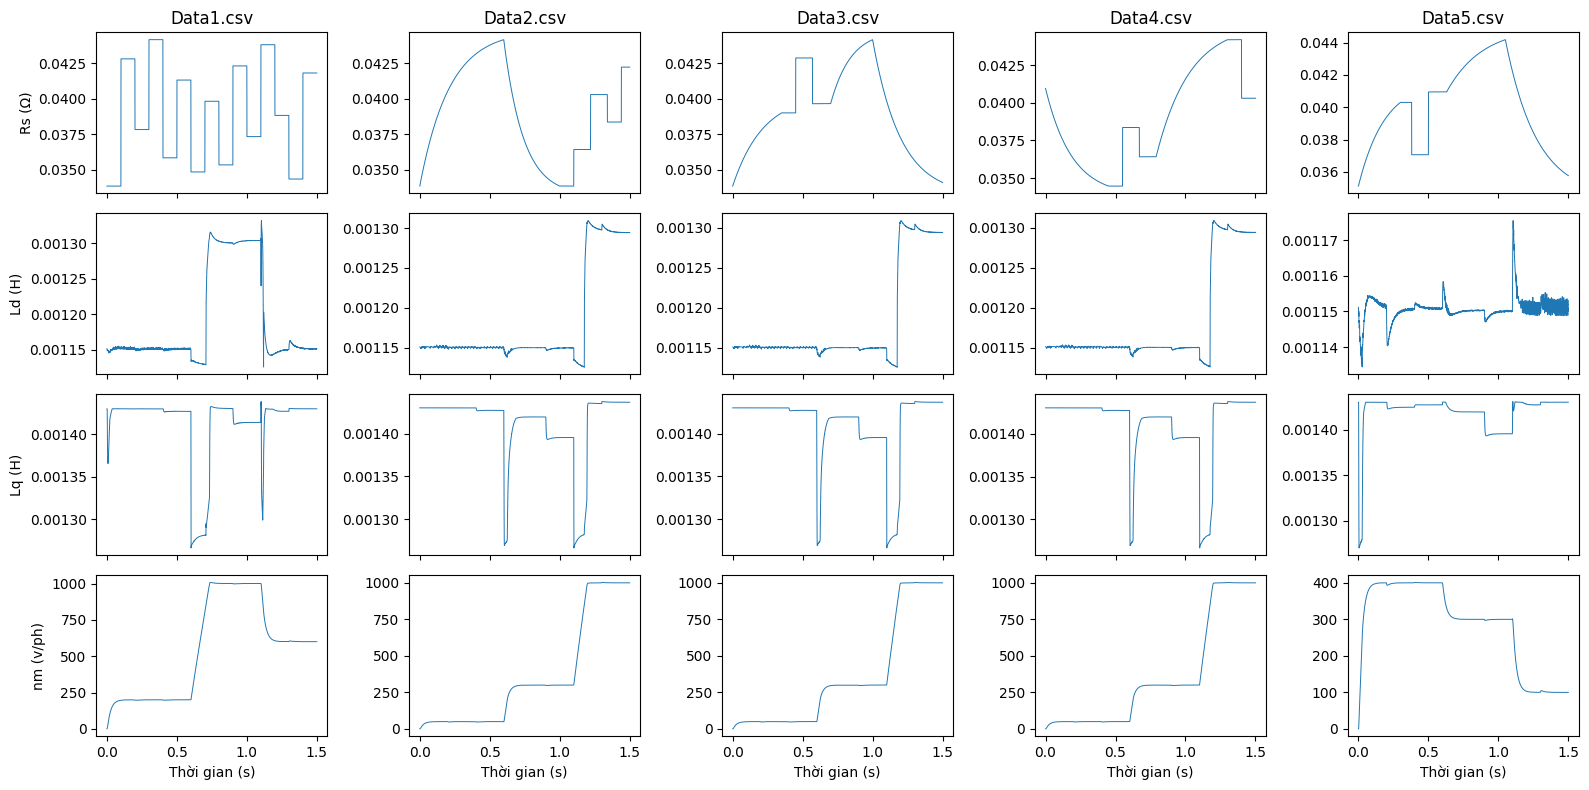

In [14]:
# Cell 3 - Vẽ biến thiên của nhãn và tốc độ theo thời gian
import matplotlib.pyplot as plt  # Thư viện vẽ đồ thị
os.makedirs(PATHS['results'], exist_ok=True)  # Đảm bảo thư mục kết quả tồn tại
fig, ax = plt.subplots(4, len(raw), figsize=(3.2 * len(raw), 8), sharex='col')  # Lưới đồ thị bốn hàng
for j, (f, df) in enumerate(raw.items()):  # Duyệt từng tệp
    for i, (c_, lab) in enumerate((('Rs', 'Rs (Ω)'), ('Ld', 'Ld (H)'), ('Lq', 'Lq (H)'), ('nm', 'nm (v/ph)'))):  # Duyệt bốn đại lượng
        ax[i, j].plot(df['Time'], df[c_], linewidth=0.7)  # Vẽ đường theo thời gian
        ax[i, j].set_ylabel(lab if j == 0 else '')  # Nhãn trục tung ở cột đầu
    ax[0, j].set_title(f)  # Tiêu đề theo tệp
    ax[-1, j].set_xlabel('Thời gian (s)')  # Nhãn trục hoành
fig.tight_layout()  # Căn chỉnh bố cục
fig.savefig(os.path.join(PATHS['results'], 'eda_labels.png'), dpi=150)  # Lưu ảnh vào Drive
plt.show()  # Hiển thị ảnh

## Cell 4 – Viết `src/data/preprocessing.py`
Các hàm: đọc và kiểm tra tệp, kiểm tra lưới thời gian, tính ωe, đạo hàm dòng điện, sai số phương trình điện áp, cờ quá độ, thống kê nhãn. ωe, did/dt, diq/dt không phải đầu vào của MLP (đầu vào chỉ là id, iq) mà là đại lượng của bộ ước lượng Rs ở sổ tay 06.

In [16]:
%%writefile /content/Parameter_Identification_of_PMSM_using_PINN_02/src/data/preprocessing.py
"""Tiền xử lý dữ liệu động cơ PMSM: kiểm tra, tính đạo hàm dòng điện, gắn cờ vận hành."""  # Mô tả mô-đun
import math  # Hàm toán học cơ bản
import numpy as np  # Thư viện số học mảng
import pandas as pd  # Thư viện bảng dữ liệu
from scipy.signal import savgol_filter  # Bộ lọc Savitzky-Golay

REQUIRED = ["Time", "Id", "Iq", "ud", "uq", "nm", "Rs", "Ld", "Lq"]  # Cột bắt buộc


def load_raw_csv(path, columns=None):  # Hàm đọc tệp thô
    """Đọc tệp CSV thô, kiểm tra cột bắt buộc và đơn vị điện cảm."""  # Mô tả hàm
    df = pd.read_csv(path)  # Đọc tệp CSV
    df.columns = [c.strip() for c in df.columns]  # Loại khoảng trắng ở tên cột
    missing = [c for c in REQUIRED if c not in df.columns]  # Tìm cột còn thiếu
    if missing:  # Nếu thiếu cột
        raise ValueError(f"Thiếu cột bắt buộc: {missing}")  # Báo lỗi rõ ràng
    if float(df["Ld"].median()) > 0.1:  # Nếu điện cảm lớn bất thường thì đơn vị là mH
        df[["Ld", "Lq"]] = df[["Ld", "Lq"]] * 1e-3  # Đổi mH sang H
    return df  # Trả về bảng dữ liệu


def check_time_grid(df):  # Hàm kiểm tra lưới thời gian
    """Tính chu kỳ lấy mẫu và độ không đều của lưới thời gian."""  # Mô tả hàm
    t = df["Time"].to_numpy(dtype=float)  # Mảng thời gian
    d = np.diff(t)  # Hiệu thời gian giữa các mẫu liên tiếp
    dt = float(np.median(d))  # Chu kỳ lấy mẫu danh định
    jitter = float(np.max(np.abs(d - dt)) / dt)  # Độ lệch tương đối lớn nhất
    return {"dt": dt, "fs": 1.0 / dt, "jitter": jitter, "n": int(len(t))}  # Trả về thống kê


def compute_omega_e(nm, pole_pairs):  # Hàm tính tốc độ góc điện
    """Đổi tốc độ cơ nm (vòng/phút) sang tốc độ góc điện ωe (rad/s)."""  # Mô tả hàm
    return np.asarray(nm, dtype=float) * 2.0 * math.pi * pole_pairs / 60.0  # ωe = p·2π·n/60


def compute_derivatives(df, dt, window, polyorder):  # Hàm tính đạo hàm dòng điện
    """Tính did/dt và diq/dt bằng bộ lọc Savitzky-Golay."""  # Mô tả hàm
    out = {}  # Từ điển kết quả
    for col, name in (("Id", "did_dt"), ("Iq", "diq_dt")):  # Duyệt hai trục
        out[name] = savgol_filter(df[col].to_numpy(dtype=float), window, polyorder, deriv=1, delta=dt, mode="interp")  # Đạo hàm theo thời gian
    return out  # Trả về hai mảng đạo hàm


def voltage_residual_numpy(df, psi_m, pole_pairs):  # Hàm sai số phương trình điện áp
    """Tính sai số phương trình điện áp d-q với tham số nhãn trong bộ dữ liệu."""  # Mô tả hàm
    w = df["omega_e"].to_numpy()  # Tốc độ góc điện
    rd = df["ud"] - (df["Rs"] * df["Id"] + df["Ld"] * df["did_dt"] - w * df["Lq"] * df["Iq"])  # Sai số trục d
    rq = df["uq"] - (df["Rs"] * df["Iq"] + df["Lq"] * df["diq_dt"] + w * df["Ld"] * df["Id"] + w * psi_m)  # Sai số trục q
    return rd.to_numpy(), rq.to_numpy()  # Trả về hai mảng sai số


def estimate_psi_m(df, min_speed_ratio=0.1):  # Hàm ước lượng Psi_m từ dữ liệu
    """Ước lượng Psi_m bằng bình phương tối thiểu từ phương trình trục q, trên các mẫu đủ nhanh và không quá độ."""  # Mô tả hàm
    w = df["omega_e"].to_numpy(dtype=float)  # Tốc độ góc điện
    y = (df["uq"] - (df["Rs"] * df["Iq"] + df["Lq"] * df["diq_dt"] + w * df["Ld"] * df["Id"])).to_numpy(dtype=float)  # Phần điện áp còn lại bằng ωe·Psi_m
    mask = np.abs(w) > min_speed_ratio * np.max(np.abs(w))  # Chỉ giữ mẫu có tốc độ đủ lớn
    if "is_transient" in df.columns:  # Nếu có cờ quá độ
        mask &= ~df["is_transient"].to_numpy(dtype=bool)  # Loại mẫu quá độ
    if int(mask.sum()) < 10:  # Không đủ mẫu để ước lượng
        raise ValueError("Không đủ mẫu tốc độ đủ lớn để ước lượng Psi_m")  # Báo lỗi rõ ràng
    return float(np.sum(w[mask] * y[mask]) / np.sum(w[mask] ** 2))  # Nghiệm bình phương tối thiểu của y = ωe·Psi_m


def flag_rs_transient(df, threshold, t_settle):  # Hàm gắn cờ quá độ Rs
    """Gắn cờ quá độ cho các mẫu nằm trong t_settle sau mỗi bước nhảy của Rs."""  # Mô tả hàm
    rs = df["Rs"].to_numpy(dtype=float)  # Mảng Rs nhãn
    t = df["Time"].to_numpy(dtype=float)  # Mảng thời gian
    rel = np.abs(np.diff(rs)) / np.maximum(np.abs(rs[:-1]), 1e-12)  # Thay đổi tương đối giữa hai mẫu
    idx = np.where(rel > threshold)[0] + 1  # Chỉ số các mẫu ngay sau bước nhảy
    flag = np.zeros(len(rs), dtype=bool)  # Mảng cờ ban đầu bằng sai
    for i in idx:  # Duyệt từng bước nhảy
        flag |= (t >= t[i]) & (t < t[i] + t_settle)  # Gắn cờ cửa sổ sau bước nhảy
    return flag, int(len(idx))  # Trả về cờ và số bước nhảy


def build_processed(df, cfg):  # Hàm dựng bảng đã xử lý
    """Dựng bảng đã xử lý gồm tín hiệu, đạo hàm, ωe và các cờ vận hành."""  # Mô tả hàm
    d, m = cfg["data"], cfg["motor"]  # Rút gọn các nhóm cấu hình
    df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)  # Loại giá trị không hợp lệ
    grid = check_time_grid(df)  # Kiểm tra lưới thời gian
    der = compute_derivatives(df, grid["dt"], d["sg_window"], d["sg_polyorder"])  # Tính đạo hàm
    out = df.copy()  # Sao chép bảng gốc
    out["did_dt"], out["diq_dt"] = der["did_dt"], der["diq_dt"]  # Thêm cột đạo hàm
    out["omega_e"] = compute_omega_e(out["nm"], m["pole_pairs"])  # Thêm cột ωe
    out["is_transient"], _ = flag_rs_transient(out, d["rs_step_threshold"], d["t_settle"])  # Thêm cờ quá độ
    half = d["sg_window"] // 2  # Số mẫu biên bị ảnh hưởng bởi bộ lọc
    out = out.iloc[half:len(out) - half].reset_index(drop=True)  # Cắt các mẫu biên
    return out.iloc[::d["stride"]].reset_index(drop=True)  # Lấy mẫu con theo bước stride


def label_stats(df_list, margin):  # Hàm thống kê nhãn
    """Tính khoảng giá trị nhãn trên tập huấn luyện, mở rộng theo biên margin."""  # Mô tả hàm
    allv = pd.concat(df_list, ignore_index=True)  # Gộp các bảng huấn luyện
    stats = {}  # Từ điển kết quả
    for c in ("Rs", "Ld", "Lq"):  # Duyệt ba tham số
        lo, hi = float(allv[c].min()), float(allv[c].max())  # Cực tiểu và cực đại
        stats[c] = {"min": lo, "max": hi, "lo": lo * (1 - margin), "hi": hi * (1 + margin)}  # Khoảng mở rộng
    return stats  # Trả về thống kê

Writing /content/Parameter_Identification_of_PMSM_using_PINN_02/src/data/preprocessing.py


## Cell 5 – Kiểm thử đơn vị trên dữ liệu mẫu
Dùng tín hiệu tổng hợp có nghiệm giải tích để kiểm tra từng hàm.

In [17]:
# Cell 5 - Kiểm thử đơn vị cho preprocessing.py bằng dữ liệu mẫu có nghiệm giải tích
import importlib  # Nạp lại mô-đun vừa ghi
import src.data.preprocessing as pp  # Mô-đun cần kiểm thử
importlib.reload(pp)  # Dùng bản mới ghi
assert abs(pp.compute_omega_e(749.45, 9) - 706.33) < 0.05, 'Sai công thức ωe'  # ωe tại tốc độ định mức
dt, n = 1e-4, 4000  # Chu kỳ mẫu và số mẫu thử
t = np.arange(n) * dt  # Trục thời gian mẫu
fq = 20.0  # Tần số tín hiệu thử (Hz)
s = pd.DataFrame({'Time': t, 'Id': -10 + 5 * np.sin(2 * np.pi * fq * t), 'Iq': 30 + 8 * np.cos(2 * np.pi * fq * t)})  # Dòng điện mẫu
der = pp.compute_derivatives(s, dt, 21, 3)  # Đạo hàm bằng Savitzky-Golay
ref = 5 * 2 * np.pi * fq * np.cos(2 * np.pi * fq * t)  # Đạo hàm giải tích của Id
assert np.max(np.abs(der['did_dt'][50:-50] - ref[50:-50])) < 0.01 * np.max(np.abs(ref)), 'Sai số đạo hàm vượt 1%'  # Kiểm tra độ chính xác
s['nm'], s['Rs'], s['Ld'], s['Lq'] = 600.0, 0.0338, 0.0012, 0.0011  # Tham số không đổi
s['Rs'] = np.where(t > 0.2, 0.0338 * 1.3, 0.0338)  # Tạo một bước nhảy Rs
flag, n_step = pp.flag_rs_transient(s, 0.005, 0.05)  # Gắn cờ quá độ
assert n_step == 1, 'Phải phát hiện đúng một bước nhảy'  # Kiểm tra số bước nhảy
assert abs(int(flag.sum()) - 500) <= 2, 'Cửa sổ quá độ phải dài 50 ms'  # Kiểm tra độ dài cửa sổ
assert not hasattr(pp, 'flag_saturation'), 'Hàm gắn cờ bão hòa đã bị loại'  # Kiểm tra đã bỏ cờ bão hòa
tmp = os.path.join(PATHS['processed'], '_tmp_mH.csv')  # Tệp tạm để thử đổi đơn vị
os.makedirs(PATHS['processed'], exist_ok=True)  # Đảm bảo thư mục tồn tại
pd.DataFrame({'Time': t[:5], 'Id': 0.0, 'Iq': 0.0, 'ud': 0.0, 'uq': 0.0, 'nm': 0.0, 'Rs': 0.03, 'Ld': 1.2, 'Lq': 1.1}).to_csv(tmp, index=False)  # Ghi tệp thử với đơn vị mH
assert pp.load_raw_csv(tmp)['Ld'].iloc[0] < 0.01, 'Chưa đổi mH sang H'  # Kiểm tra đổi đơn vị
os.remove(tmp)  # Xóa tệp tạm
s['ud'] = s['Rs'] * s['Id'] + s['Ld'] * der['did_dt'] - pp.compute_omega_e(s['nm'], 9) * s['Lq'] * s['Iq']  # Điện áp d theo mô hình
s['uq'] = s['Rs'] * s['Iq'] + s['Lq'] * der['diq_dt'] + pp.compute_omega_e(s['nm'], 9) * (s['Ld'] * s['Id'] + cfg['motor']['psi_m'])  # Điện áp q theo mô hình
s['did_dt'], s['diq_dt'], s['omega_e'] = der['did_dt'], der['diq_dt'], pp.compute_omega_e(s['nm'], 9)  # Thêm cột phụ
rd, rq = pp.voltage_residual_numpy(s, cfg['motor']['psi_m'], 9)  # Sai số phương trình khi dữ liệu nhất quán
assert np.max(np.abs(rd)) < 1e-6 and np.max(np.abs(rq)) < 1e-6, 'Sai số phải bằng 0 với dữ liệu nhất quán'  # Kiểm tra bằng 0
psi_hat = pp.estimate_psi_m(s)  # Ước lượng Psi_m từ dữ liệu nhất quán
assert abs(psi_hat - cfg['motor']['psi_m']) < 1e-9, 'Ước lượng Psi_m phải khôi phục giá trị dùng để sinh dữ liệu'  # Kiểm tra khôi phục
assert abs(psi_hat / 0.23890939 - 1.0) > cfg['data']['psi_check_tol_pct'] / 100.0, 'Phép kiểm tra phải phân biệt được Psi_m mới với giá trị cũ 0,2389'  # Kiểm tra khả năng phân biệt
TESTS_OK = True  # Bật cờ cho phép đẩy mã
print('Toàn bộ kiểm thử đơn vị đạt')  # Thông báo

Toàn bộ kiểm thử đơn vị đạt


## Cell 6 – Xử lý toàn bộ tệp và lưu thống kê nhãn
Mỗi tệp được lưu thành `*_processed.csv.gz`; khoảng giá trị nhãn tính chỉ trên tập huấn luyện (tránh rò rỉ) và lưu vào `stats.json`. Khoảng của Ld, Lq là cận đầu ra của MLP; khoảng của Rs dùng để kiểm tra nhãn Rs có nằm trong dải 20–128 °C hay không.

In [18]:
# Cell 6 - Xử lý toàn bộ tệp thô và lưu thống kê nhãn
import json  # Ghi thống kê JSON
processed = {}  # Từ điển bảng đã xử lý
for f in cfg['data']['raw_files']:  # Duyệt từng tệp thô
    df = pp.load_raw_csv(os.path.join(PATHS['raw'], f))  # Đọc và kiểm tra tệp
    out = pp.build_processed(df, cfg)  # Dựng bảng đã xử lý
    out.to_csv(os.path.join(PATHS['processed'], f.replace('.csv', '_processed.csv.gz')), index=False, compression='gzip')  # Lưu nén
    grid = pp.check_time_grid(df)  # Thống kê lưới thời gian
    print(f, '| mẫu sau xử lý:', len(out), '| Ts =', grid['dt'], '| độ lệch lưới =', grid['jitter'], '| tỷ lệ quá độ =', round(float(out['is_transient'].mean()), 4))  # In thống kê
    processed[f] = out  # Lưu vào từ điển
train_frames = [processed[f] for f in cfg['data']['split']['train']]  # Các bảng của tập huấn luyện
stats = pp.label_stats(train_frames, cfg['data']['bound_margin'])  # Khoảng giá trị nhãn
with open(os.path.join(PATHS['processed'], 'stats.json'), 'w', encoding='utf-8') as fh:  # Mở tệp thống kê
    json.dump(stats, fh, indent=1)  # Ghi thống kê
display(pd.DataFrame(stats).T)  # Hiển thị bảng thống kê nhãn
rs_a, rs_b = cfg['motor']['rs_20c'], cfg['motor']['rs_128c']  # Rs tại 20 °C và 128 °C theo yêu cầu cập nhật
ok_rs = stats['Rs']['min'] >= 0.95 * rs_a and stats['Rs']['max'] <= 1.05 * rs_b  # Nhãn Rs nằm trong dải nhiệt độ 20-128 °C
print('Dải Rs của nhãn huấn luyện:', round(stats['Rs']['min'], 6), 'đến', round(stats['Rs']['max'], 6), '| dải 20-128 °C:', rs_a, 'đến', rs_b)  # In so sánh
print('Phù hợp dải nhiệt độ 20-128 °C' if ok_rs else 'CẢNH BÁO: dải Rs của nhãn lệch dải 20-128 °C [TBD]')  # Kết luận
allv = pd.concat(train_frames, ignore_index=True)  # Gộp các bảng huấn luyện
for key, col in (('ld_ref', 'Ld'), ('lq_ref', 'Lq')):  # Kiểm tra giá trị tham chiếu của hàm mất mát
    med, ref = float(allv[col].median()), cfg['motor'][key]  # Trung vị nhãn huấn luyện và giá trị cấu hình
    print(f'{col}: trung vị huấn luyện = {med:.6f} H | {key} cấu hình = {ref} H |', 'phù hợp' if abs(ref / med - 1.0) <= 0.1 else f'CẢNH BÁO: {key} lệch quá 10% so với trung vị, cần cập nhật config [TBD]')  # Kết luận

Data1.csv | mẫu sau xử lý: 299980 | Ts = 4.999999999921734e-06 | độ lệch lưới = 1.1102230246425351e-10 | tỷ lệ quá độ = 0.4667
Data2.csv | mẫu sau xử lý: 299980 | Ts = 4.999999999921734e-06 | độ lệch lưới = 1.1102230246425351e-10 | tỷ lệ quá độ = 0.1334
Data3.csv | mẫu sau xử lý: 299980 | Ts = 4.999999999921734e-06 | độ lệch lưới = 1.1102230246425351e-10 | tỷ lệ quá độ = 0.0667
Data4.csv | mẫu sau xử lý: 299980 | Ts = 4.999999999921734e-06 | độ lệch lưới = 1.1102230246425351e-10 | tỷ lệ quá độ = 0.1
Data5.csv | mẫu sau xử lý: 299980 | Ts = 4.999999999921734e-06 | độ lệch lưới = 1.1102230246425351e-10 | tỷ lệ quá độ = 0.0667


,min,max,lo,hi
Rs,0.033828,0.044186,0.027062,0.053023
Ld,0.001125,0.001332,0.000900,0.001598
Lq,0.001266,0.001438,0.001013,0.001726


Dải Rs của nhãn huấn luyện: 0.033828 đến 0.044186 | dải 20-128 °C: 0.03383 đến 0.04828
Phù hợp dải nhiệt độ 20-128 °C
Ld: trung vị huấn luyện = 0.001151 H | ld_ref cấu hình = 0.00115 H | phù hợp
Lq: trung vị huấn luyện = 0.001427 H | lq_ref cấu hình = 0.00143 H | phù hợp


## Cell 7 – Kiểm tra tính nhất quán của phương trình điện áp
Tính sai số phương trình d-q với tham số nhãn; giá trị lớn cho thấy mô hình điện và bộ dữ liệu không khớp, khi đó Rs tính đại số ở sổ tay 06 sẽ lệch theo. Cell này cũng ước lượng Psi_m bằng bình phương tối thiểu từ phương trình trục q và so với `psi_m` trong cấu hình (chỉ để kiểm tra, không hiệu chỉnh Psi_m); ngưỡng lấy từ `consistency_rms_pu` và `psi_check_tol_pct` (cả hai `[TBD]`, cần hiệu chỉnh theo dữ liệu thật).

In [19]:
# Cell 7 - Kiểm tra tính nhất quán của phương trình điện áp với nhãn của bộ dữ liệu
u_base = cfg['motor']['u_dc'] / 3 ** 0.5  # Điện áp cơ sở (V)
tol_rms, tol_psi = cfg['data']['consistency_rms_pu'], cfg['data']['psi_check_tol_pct']  # Ngưỡng lấy từ cấu hình
psi_cfg = cfg['motor']['psi_m']  # Psi_m trong cấu hình
consistency = {}  # Từ điển kết quả
for f, out in processed.items():  # Duyệt từng tệp
    rd, rq = pp.voltage_residual_numpy(out, psi_cfg, cfg['motor']['pole_pairs'])  # Sai số hai trục
    psi_hat = pp.estimate_psi_m(out)  # Psi_m ước lượng từ dữ liệu
    consistency[f] = {'rms_d_pu': float(np.sqrt(np.mean(rd ** 2)) / u_base), 'rms_q_pu': float(np.sqrt(np.mean(rq ** 2)) / u_base), 'max_pu': float(max(np.abs(rd).max(), np.abs(rq).max()) / u_base), 'psi_m_hat': psi_hat, 'psi_dev_pct': float((psi_hat / psi_cfg - 1.0) * 100.0)}  # Sai số tương đối so với điện áp cơ sở và độ lệch Psi_m
    print(f, consistency[f])  # In kết quả
with open(os.path.join(PATHS['results'], 'physics_consistency.json'), 'w', encoding='utf-8') as fh:  # Mở tệp kết quả
    json.dump(consistency, fh, indent=1)  # Ghi kết quả
worst = max(v['rms_q_pu'] for v in consistency.values())  # Sai số RMS lớn nhất trục q
worst_psi = max(abs(v['psi_dev_pct']) for v in consistency.values())  # Độ lệch Psi_m lớn nhất
print('Kết luận RMS:', 'nhất quán' if worst < tol_rms else f'CẢNH BÁO: sai số RMS trên {tol_rms * 100:.1f}% điện áp cơ sở, cần xem xét lại mô hình hoặc Psi_m [TBD]')  # Kết luận theo ngưỡng cấu hình
print('Kết luận Psi_m:', 'phù hợp với cấu hình' if worst_psi < tol_psi else f'CẢNH BÁO: Psi_m ước lượng lệch quá {tol_psi:.1f}% so với {psi_cfg} Wb [TBD]')  # Kết luận về Psi_m

Data1.csv {'rms_d_pu': 0.007600526521167134, 'rms_q_pu': 0.006323408914407287, 'max_pu': 0.6544975234836062, 'psi_m_hat': 0.23149124747927075, 'psi_dev_pct': -0.18397565859906706}
Data2.csv {'rms_d_pu': 0.0047380057687718006, 'rms_q_pu': 0.004526501693980061, 'max_pu': 0.581724414048615, 'psi_m_hat': 0.23147510416047762, 'psi_dev_pct': -0.19093644834446977}
Data3.csv {'rms_d_pu': 0.004681236918711146, 'rms_q_pu': 0.0044836252600187945, 'max_pu': 0.5810068270922583, 'psi_m_hat': 0.23149709590013137, 'psi_dev_pct': -0.18145389535600964}
Data4.csv {'rms_d_pu': 0.004713462211988274, 'rms_q_pu': 0.004487036747812579, 'max_pu': 0.5761405724848889, 'psi_m_hat': 0.23146283799563944, 'psi_dev_pct': -0.19622545957662663}
Data5.csv {'rms_d_pu': 0.006138418770296164, 'rms_q_pu': 0.002247191480288063, 'max_pu': 0.07555122209691105, 'psi_m_hat': 0.23181168837310223, 'psi_dev_pct': -0.04580570009328211}
Kết luận RMS: nhất quán
Kết luận Psi_m: CẢNH BÁO: Psi_m ước lượng lệch quá 0.0% so với 0.23191792 

## Cell 8 – Bước 4: đẩy lên GitHub

In [20]:
# Cell cuối - Bước 4: đẩy tệp đã kiểm thử đạt lên GitHub
assert TESTS_OK, 'Chưa đạt toàn bộ kiểm thử, không được đẩy mã'  # Chặn đẩy mã khi kiểm thử chưa đạt
push_files(['src/data/preprocessing.py'], 'Thêm preprocessing.py')  # Đẩy các tệp lên nhánh main

To https://github.com/maivu18082005-hub/Parameter_Identification_of_PMSM_using_PINN_02.git
   ff74fe8..db72d3c  HEAD -> main

